## Importing libraries

In [1]:
import numpy as np
import pandas as pd
import pickle
from scipy import signal
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.lines import Line2D
import seaborn as sns
import os

from statsmodels.stats.weightstats import ttest_ind
import statsmodels.stats. multitest as multi

## Defining original functions

In [2]:
def bpf(e, fs, Wn, order):
    """
    Bandpass butterworth filter, returning filtered timeseries data.
    This depend on scipy signal module.

    Parameters
    ----------
    e: numpy array
        timeseries data
    fs: float
        sampling rate
    Wn: array_like
        A scalar or length-2 sequence giving the critical frequencies.

    Returns
    ----------
    numpy array
         filtered timeseries data
    """
    b, a = signal.iirfilter(order, Wn, btype = 'bandpass',
                        analog = False, ftype='butter', fs = fs)
    w, h = signal.freqz(b, a, fs=fs)

#    fig, ax = plt.subplots()
#    plt.grid(which="both")
#    ax.plot(w, 20*np.log(abs(h)))
#    ax.axis((0, 100, -100, 10))
#    ax.set_ylabel('Amplitude [dB]')
#    ax.set_xlabel('Freq [Hz]')

    return signal.filtfilt(b, a, e)

In [3]:
def seg_ave(list_tpeak, list_data, N):
    """
    Given lists of time and data, the function calculates averaged values of data in evenly divided segments.

    Parameters
    ----------
    list_tpeak: list
        list of time (float)
    list_data: list
        list of values (float)
    N: int
        number of segments

    Returns
    ----------
    ave_data: numpy array
        averaged values in N segments

    """
    N_list=len(list_tpeak)

    ave_data=np.zeros((N_list, N))

    for i in range(N_list):
        array_data=np.array(list_data[i])
        array_t=np.array(list_tpeak[i])
        seg_t = np.floor((array_t-array_t.min())/(array_t.max()-array_t.min())*N).astype('int64')
        seg_t[seg_t==N]=N-1

        for j in range(N):
            ave_data[i, j]=np.mean(array_data[seg_t==j])
    return ave_data

In [4]:
# pickle EEG data is based on this class/structure
class EEG_data:
    def __init__(self, label, time, eeg):
        self.time = time
        self.eeg = eeg
        self.label = label

## config: data file names

In [5]:
# filenames

dict_filenames = {
    'evolving_pt1': 'data/hyp_evolving_pt1.pickle',
    'aborted_pt1': 'data/hyp_aborted_pt1.pickle',
    'evolving_pt2': 'data/hyp_evolving_pt2.pickle',
    'aborted_pt2': 'data/hyp_aborted_pt2.pickle'
}

# loading data
dict_list_hyp = {}

for k in dict_filenames.keys():
    with open(dict_filenames[k], 'rb') as f:
        dict_list_hyp[k] = pd.read_pickle(f)

## Loading data and check each EEG plot

In [6]:
for k in dict_list_hyp.keys():
    print('Number of HYP, '+k+': ', len(dict_list_hyp[k]))

Number of HYP, evolving_pt1:  50
Number of HYP, aborted_pt1:  35
Number of HYP, evolving_pt2:  11
Number of HYP, aborted_pt2:  9


evolving_pt1


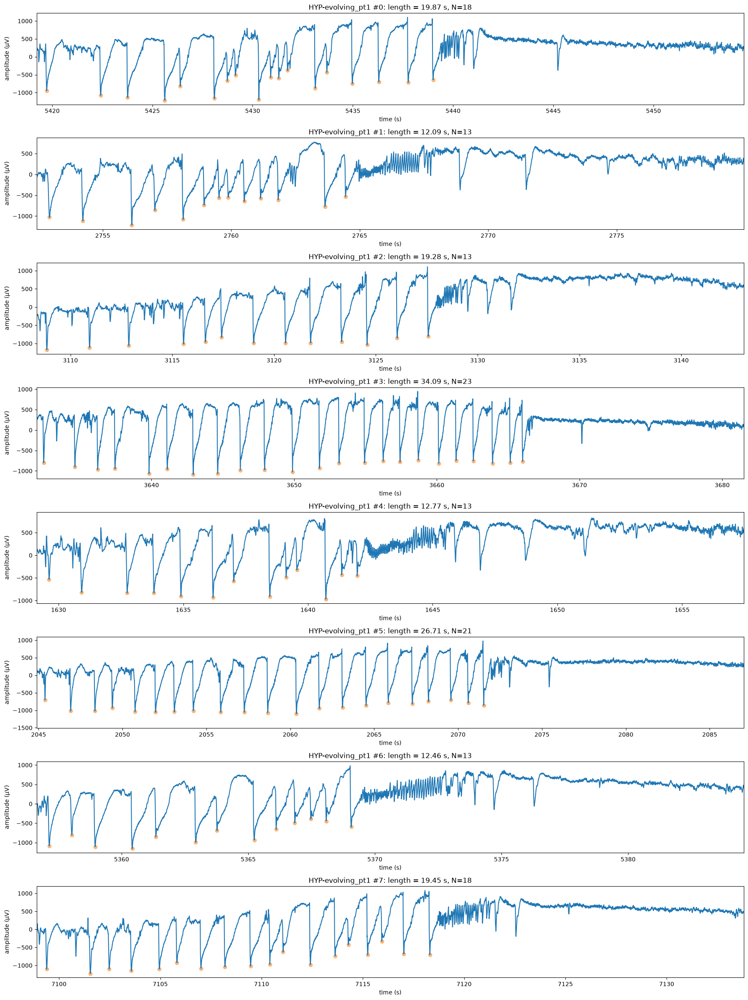

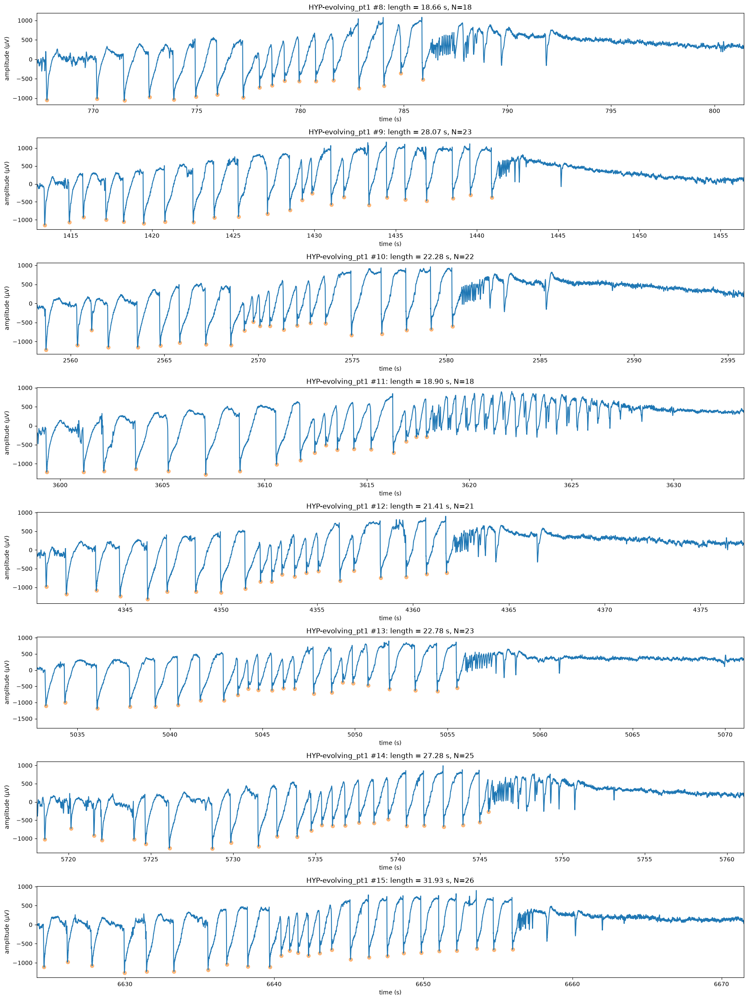

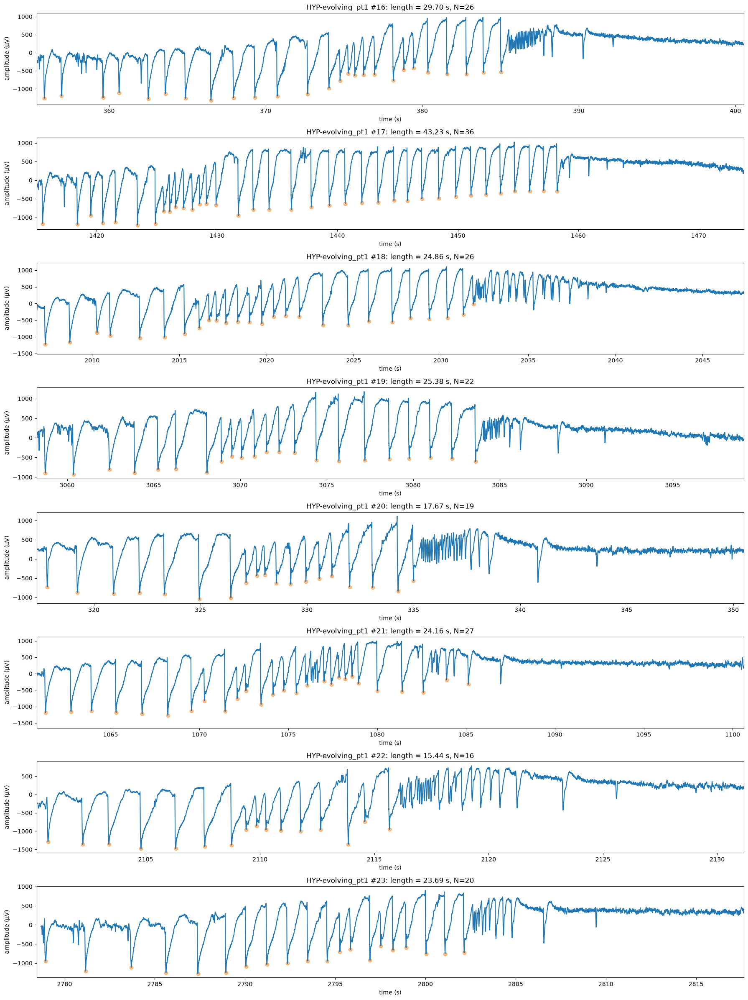

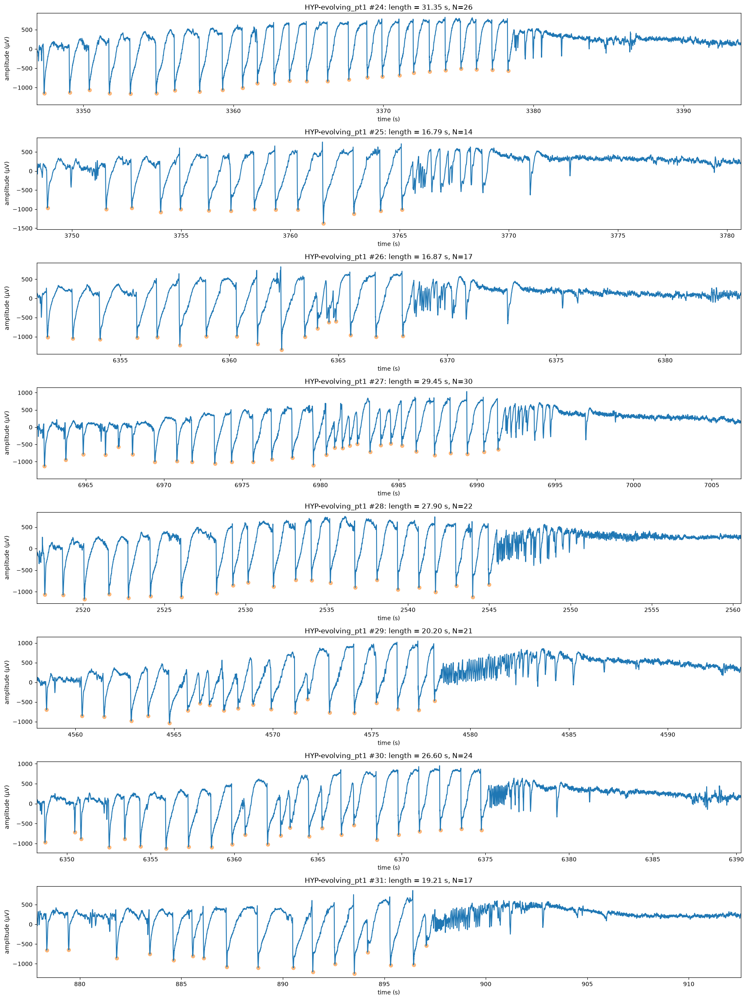

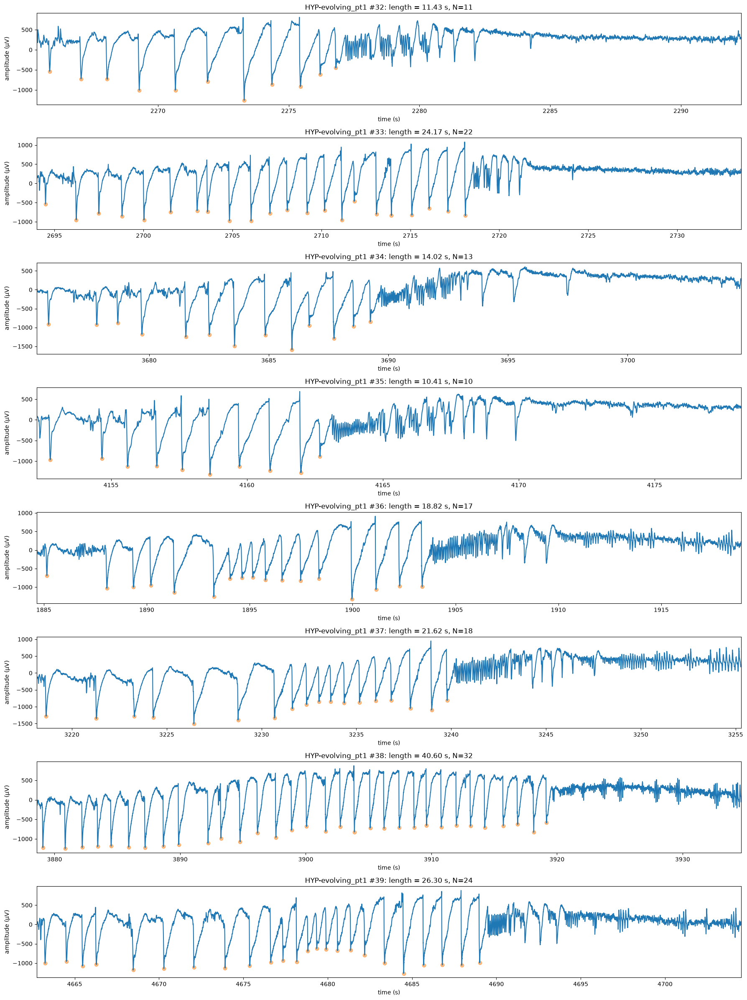

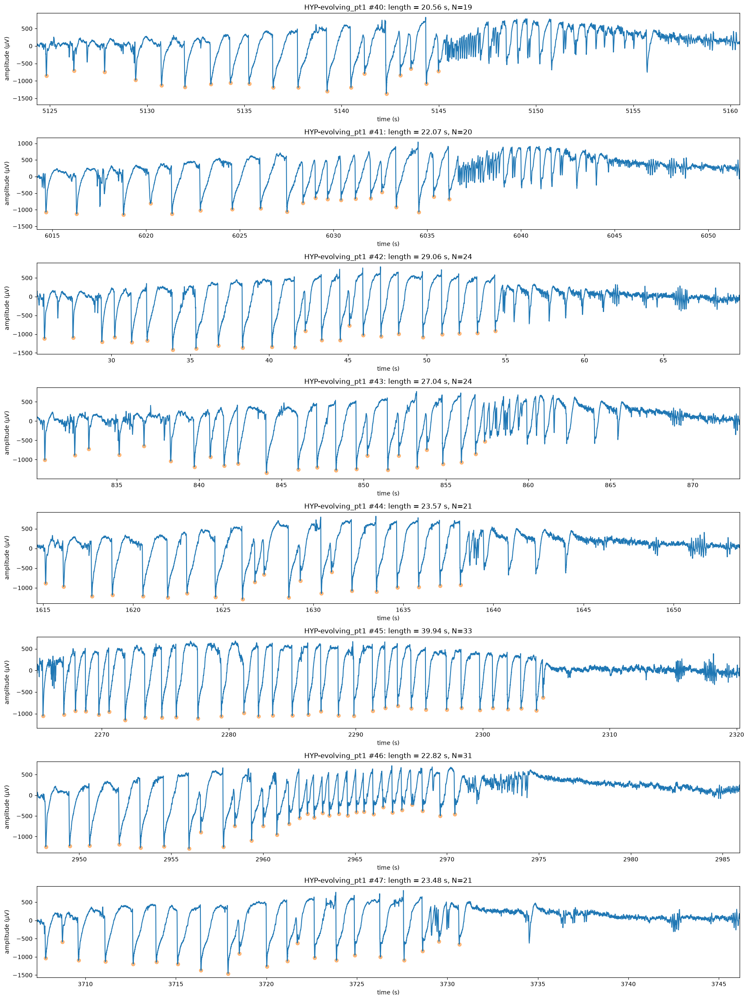

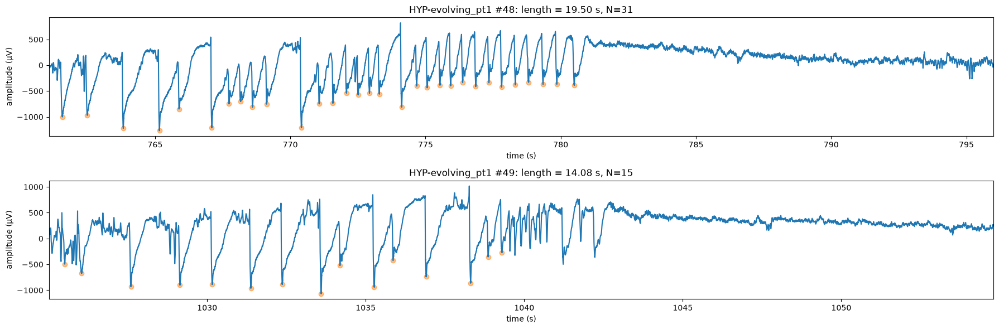

aborted_pt1


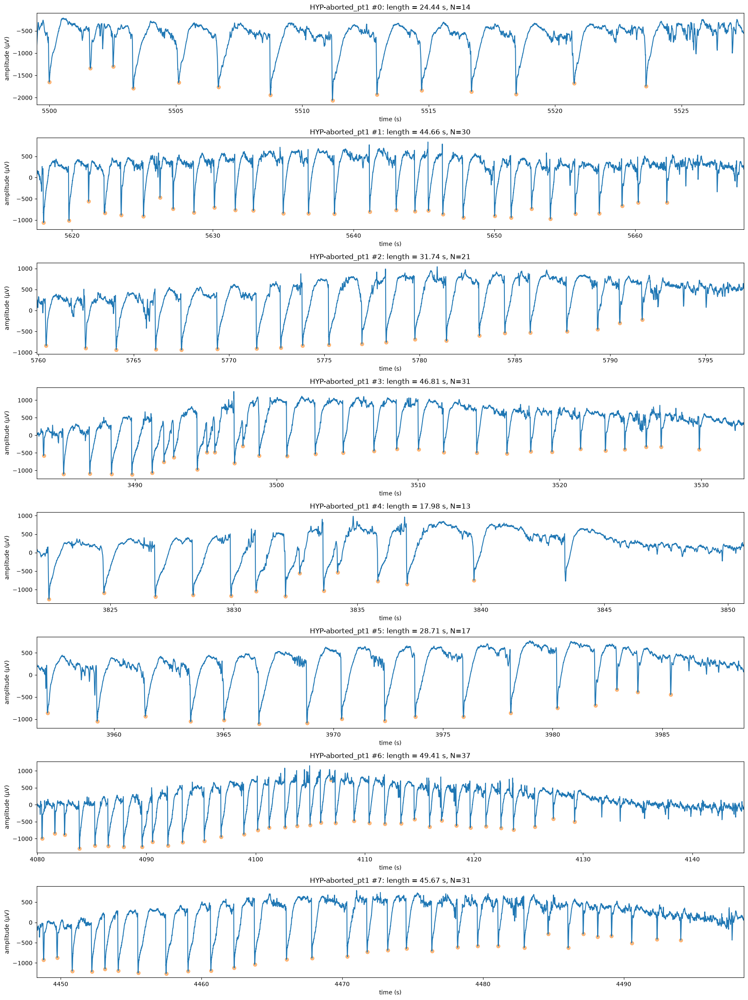

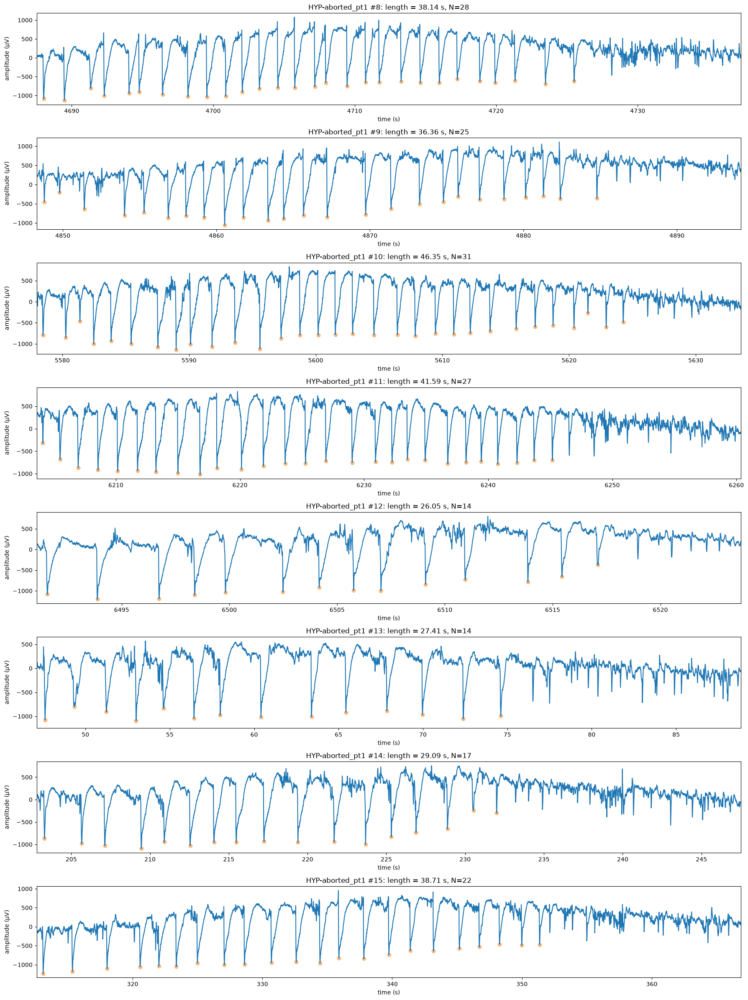

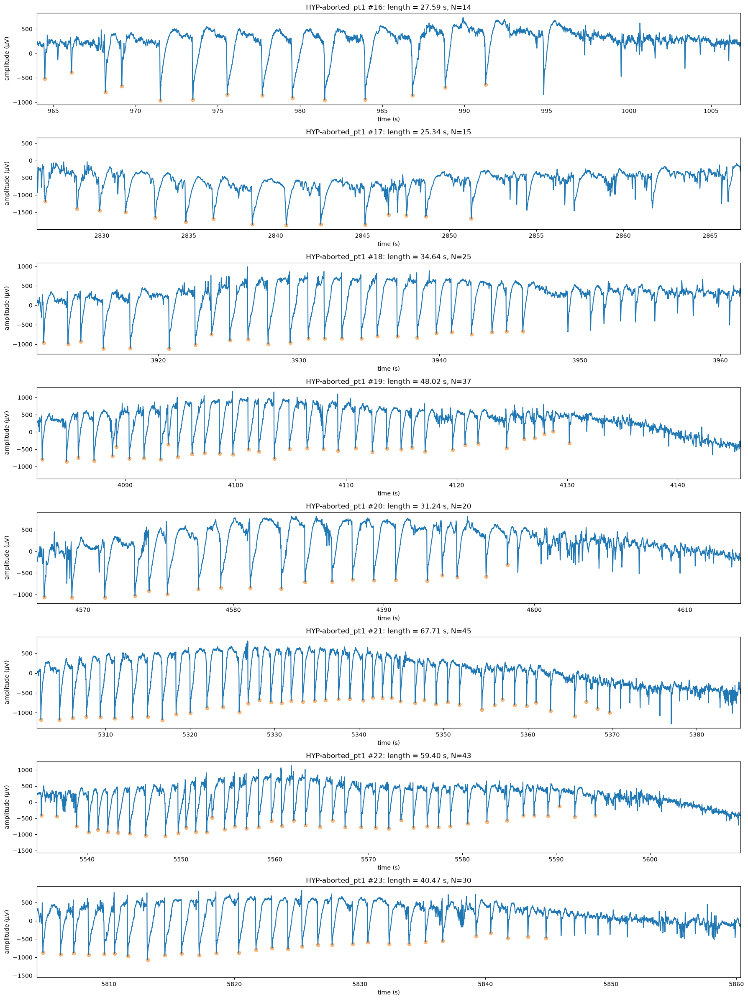

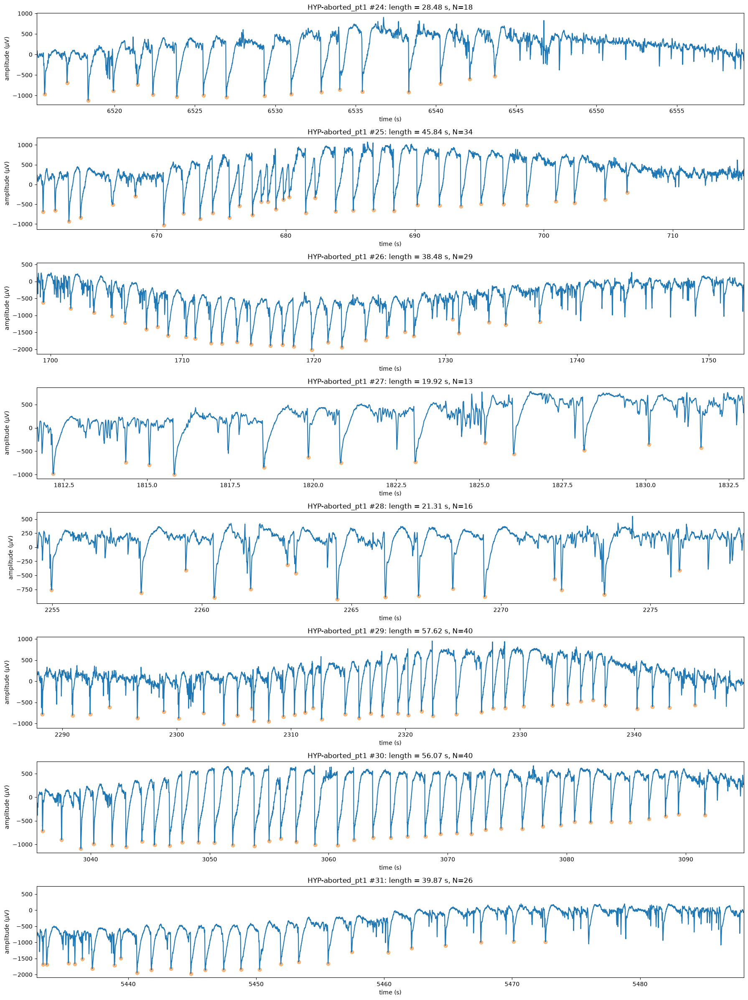

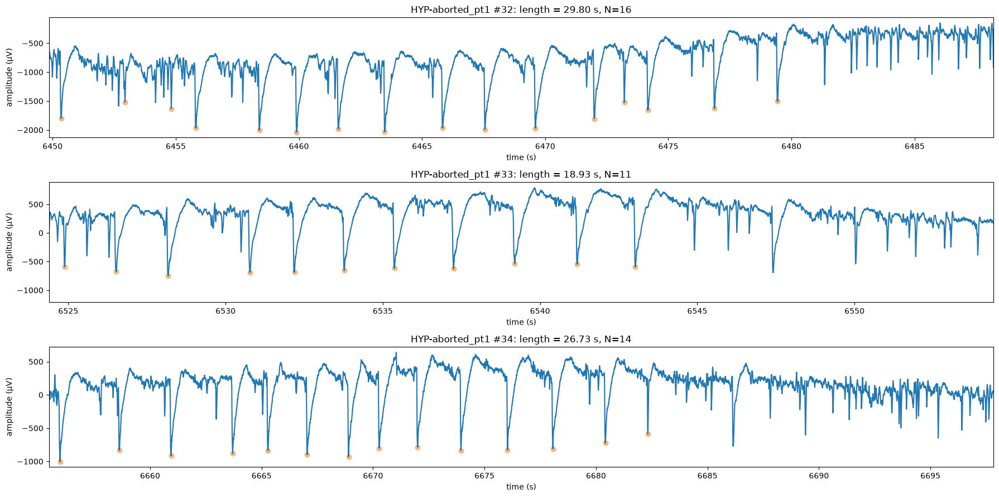

evolving_pt2


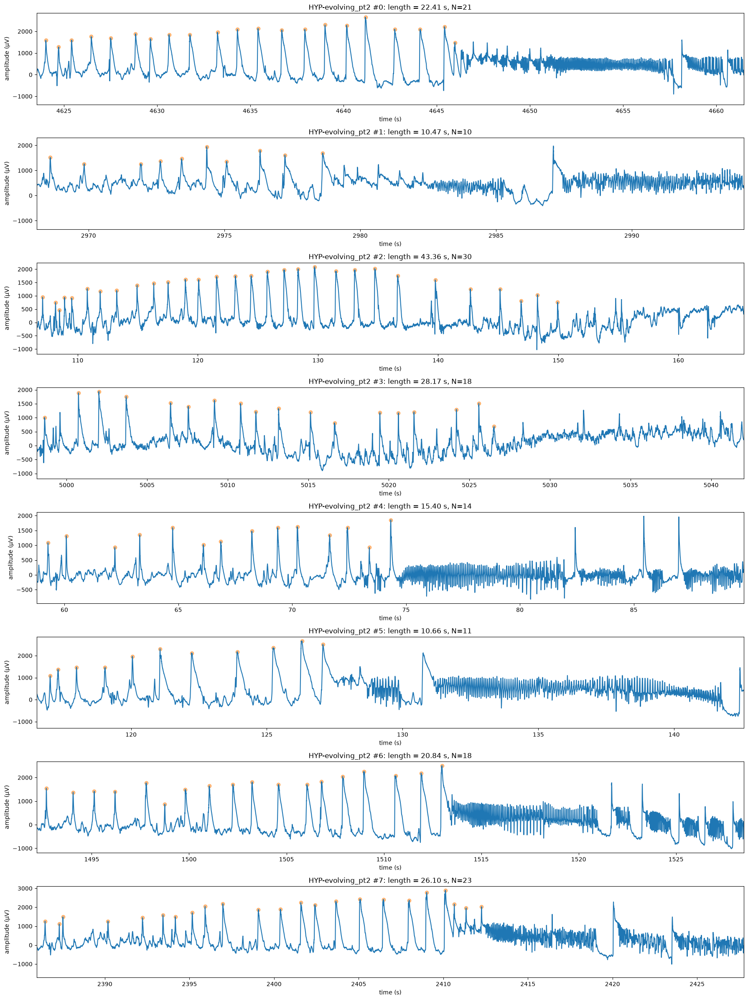

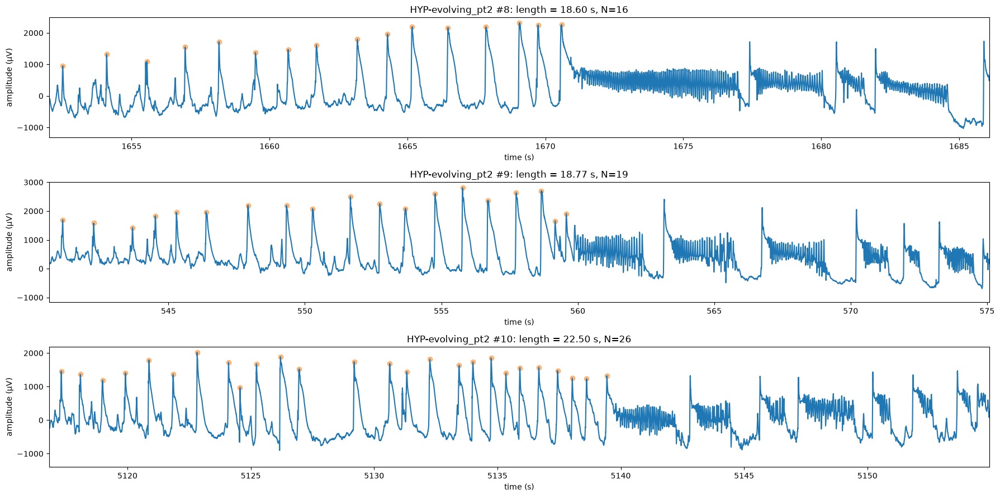

aborted_pt2


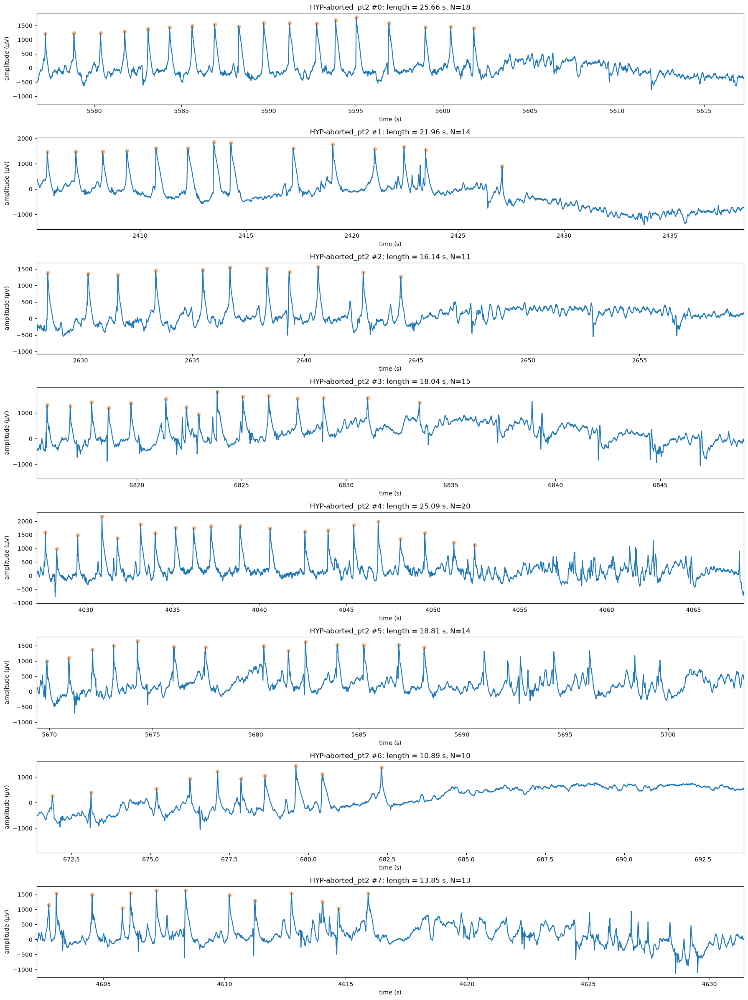

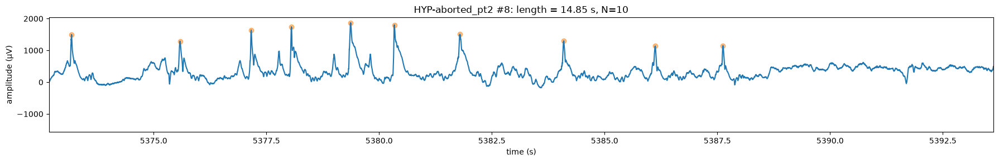

In [7]:
# show hyp and save to pdf

os.makedirs('./pdf', exist_ok=True)

for k, v in dict_list_hyp.items():
    print(k)

    with PdfPages(os.path.join('pdf', k+'_plots.pdf')) as pdf:

        len_eeg = len(v)
        plots_per_page = 8

        for i, l in enumerate(v):
            n_ax = i%plots_per_page
            if n_ax==0:
                n_page = (i//plots_per_page)+1
                rest_ax = min(n_page*plots_per_page, len_eeg)-i
                fig, ax = plt.subplots(rest_ax, 1, figsize=(18, 3*rest_ax), squeeze=False)

            ax[n_ax, 0].plot(l.time, l.eeg)
            ax[n_ax, 0].set_title('HYP-'+k+' #{}: length = {:.2f} s, N={}'.format(i, l.np_data[-1, 1]-l.np_data[0, 0], l.np_data.shape[0]))
            ax[n_ax, 0].set_xlabel('time (s)')
            ax[n_ax, 0].set_ylabel('amplitude (\u03bcV)')
            for ind in range(l.np_data.shape[0]):
                ax[n_ax, 0].scatter(l.np_data[ind, 4], l.np_data[ind, 5], color='tab:orange', alpha=0.5)
            ax[n_ax, 0].set_xlim((l.np_data[0, 4]-0.5, min(l.np_data[-1, 4]+0.5+15, l.time[-1])))
            if n_ax==(rest_ax-1):
                plt.tight_layout()
                pdf.savefig()
                plt.show()

## Calculating area under envelope (integral of inst. amp), averaged over each segment

<div>
The calculated data is stored in df_HYP as pandas dataframe.
</div>

In [8]:
def calculate_area_under_envelope(list_hyp, hyp_type):
    '''
    Creates pandas dataframe of area under envelope (area of instantaneous amplitude) averaged over 5 segments.
    Input data list_hyp must be a list of specific EEG_data class with EEG data and discharge data.

    Parameters;
    ----------
    list_hyp: list
        list of EEG class_data
    hyp_type: str
        a label for the type of EEG_class data

    Returns:
        df_HYP: pandas DataFrame
            pandas dataframe of calculated data
        list_list_iamp_area: list
            nested list, contains area under envelope of each discharge for each EEG_class data.
        list_list_t_peak: list
            nested list, contains time point difference from the first discharge for each EEG_class data.
    '''
    fs = 2000   #sampling rate
    backward_steps = 200
    forward_steps = 600
    filter_order = 4
    n_segment = 5

    cols = ['type', 'bp', 'n', 'segment1', 'segment2', 'segment3', 'segment4', 'segment5']
    cols_seg = ['segment1', 'segment2', 'segment3', 'segment4', 'segment5']
    df_HYP = pd.DataFrame()
    list_list_iamp_area = []
    list_list_t_peak = []

    # setting bandpass filter frequencies
    bandpass = []
    for i in range(2, 15):
        bandpass.append((i*40, (i+1)*40))


    for bp in bandpass:
        list_iamp_area=[]
        list_t_peak=[]
        for l in list_hyp:
            eeg=l.eeg
            time=l.time
            t_peak=l.np_data[:, 4]

            hilbert=np.abs(signal.hilbert(bpf(eeg, fs, bp, filter_order)))

            inst_amp_area = []

            for t in t_peak:
                index_t = np.argmin(np.abs(time-t))
                inst_amp_area.append(1/fs*hilbert[index_t-backward_steps:index_t+forward_steps].sum())
            list_iamp_area.append(np.array(inst_amp_area))
            list_t_peak.append(t_peak-t_peak[0])
        # concat df
        temp_df = pd.DataFrame(seg_ave(list_t_peak, list_iamp_area, n_segment), columns=cols_seg)
        temp_df['type'] = hyp_type
        temp_df['bp'] = str(bp)
        temp_df['n'] = np.arange(temp_df.shape[0])
        temp_df = temp_df.reindex(cols, axis=1)
        if len(df_HYP)==0:
            df_HYP=temp_df
        else:
            df_HYP = pd.concat([df_HYP, temp_df], ignore_index=True)

        # keep data as list
        list_list_iamp_area.append(list_iamp_area)
        list_list_t_peak.append(list_t_peak)

    return df_HYP, list_list_iamp_area, list_list_t_peak

In [9]:
dict_df_HYP = {}

for k, v in dict_list_hyp.items():
    hyp_type, pt = k.split('_')

    dict_df_HYP[k], _, _ = calculate_area_under_envelope(v, hyp_type)
    dict_df_HYP[k]['pt'] = pt

df_HYP = pd.concat(dict_df_HYP.values(), ignore_index=True)

In [10]:
list_bp = [str(bp) for bp in df_HYP['bp'].unique()]

In [11]:
df_HYP_melt = pd.melt(df_HYP, id_vars=['pt', 'bp', 'type'], value_vars = ['segment'+str(i) for i in range(1, 6)], var_name='segment', value_name='area')

In [12]:
def plot_area_vs_segment(pt='pt1', yscale='linear', errorbar=None, err_style='bars', output_filename=None, dpi=300):
    fig, ([[ax0, ax1], [ax2, ax3]]) = plt.subplots(2, 2, figsize=(10, 6))
    list_ax = [ax0, ax1, ax2, ax3]
    list_len_bp = [3, 3, 3, 4]
    list_bp_set = [list_bp[sum(list_len_bp[:i]):sum(list_len_bp[:i+1])] for i in range(len(list_len_bp))]

    def plot_func(data, ax):
        return sns.lineplot(data=data, x='segment', y='area', hue='bp', style='type', errorbar=errorbar, err_style=err_style, ax=ax)

    plot = []
    if yscale=='log':
        ylabel = 'area (\u03bcV.s, log scale)'
    else:
        ylabel = 'area (\u03bcV.s)'

    for i, ax in enumerate(list_ax):
        sub_df_HYP_melt = df_HYP_melt[(df_HYP_melt['bp'].isin(list_bp_set[i]))&(df_HYP_melt['pt']==pt)]
        plot.append(plot_func(sub_df_HYP_melt, ax))
        plot[-1].set(yscale=yscale)
        plot[-1].xaxis.set_ticks([0, 1, 2, 3, 4])
        plot[-1].xaxis.set_ticklabels([1, 2, 3, 4, 5])
        plot[-1].set_ylabel(ylabel)
        ax.legend(loc='upper left', bbox_to_anchor=(1.05, .85))
    fig.suptitle('Area under envelope vs segment: '+pt.upper(), fontsize=16)
    plt.tight_layout()
    if output_filename!=None:
        os.makedirs('figures', exist_ok=True)
        fig.savefig(os.path.join('figures', output_filename), dpi=dpi, facecolor='white')
    plt.show()

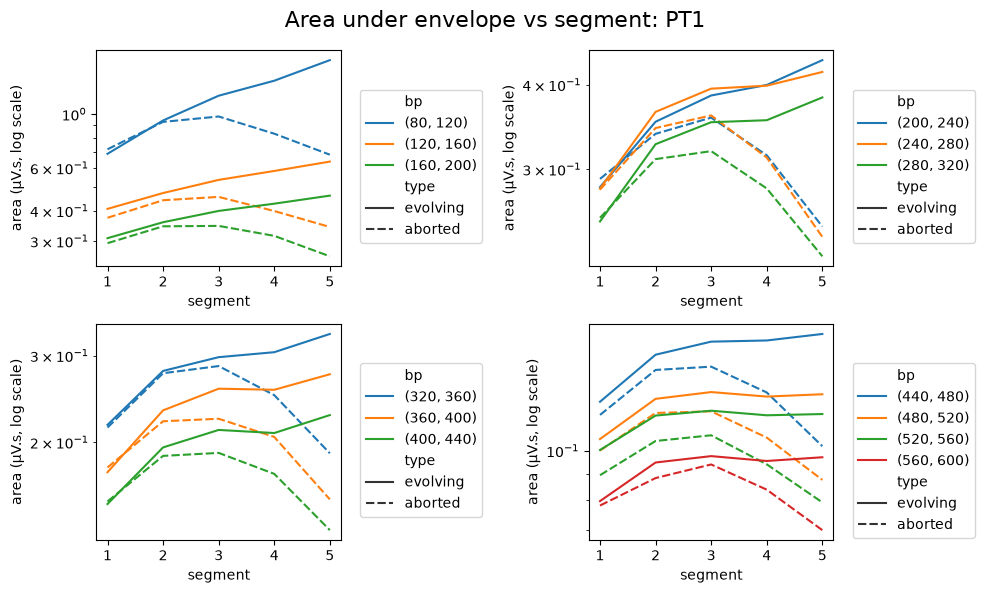

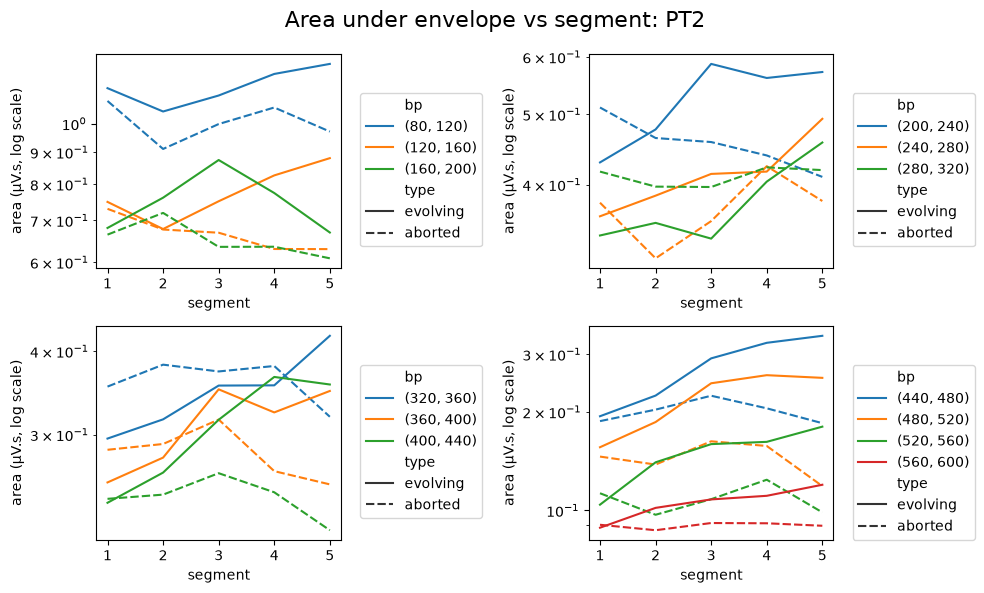

In [13]:
plot_area_vs_segment(pt='pt1', yscale='log', output_filename='area_under_envelope_pt1.tiff', dpi=300)
plot_area_vs_segment(pt='pt2', yscale='log', output_filename='area_under_envelope_pt2.tiff', dpi=300)

In [14]:
def plot_area_vs_segment_onefig(pt='pt1', yscale='linear', errorbar=None, err_style='bars', output_filename=None, dpi=300):
    fig, ax = plt.subplots(figsize=(8, 10))

    if yscale=='log':
        ylabel = 'area (\u03bcV.s, log scale)'
    else:
        ylabel = 'area (\u03bcV.s)'

    sub_df_HYP_melt = df_HYP_melt[df_HYP_melt['pt']==pt]

    plot = sns.lineplot(
        data=sub_df_HYP_melt, x='segment', y='area', hue='bp', style='type',
        errorbar=errorbar, err_style=err_style, ax=ax, palette='tab20')
    plot.set(yscale=yscale)
    plot.xaxis.set_ticks([0, 1, 2, 3, 4])
    plot.xaxis.set_ticklabels([1, 2, 3, 4, 5])
    plot.set_ylabel(ylabel)
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, .85))
    fig.suptitle('Area under envelope vs segment: '+pt.upper(), fontsize=16)
    plt.tight_layout()
    if output_filename!=None:
        os.makedirs('figures', exist_ok=True)
        fig.savefig(os.path.join('figures', output_filename), dpi=dpi, facecolor='white')
    plt.show()

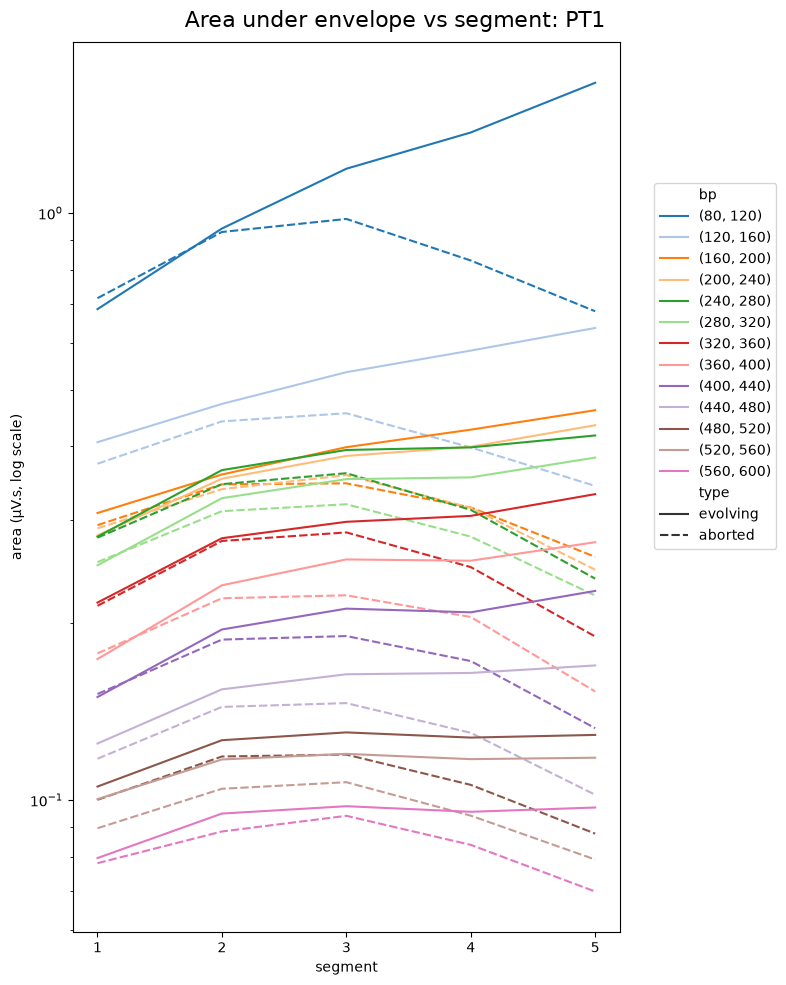

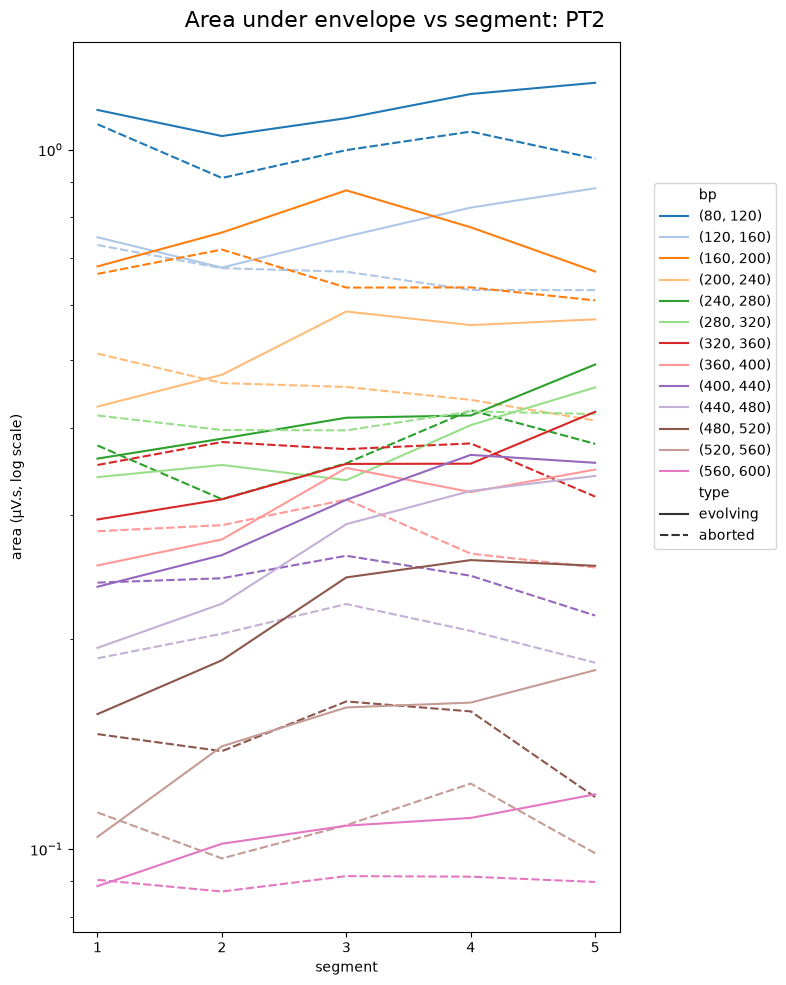

In [15]:
plot_area_vs_segment_onefig(pt='pt1', yscale='log')
plot_area_vs_segment_onefig(pt='pt2', yscale='log')

In [16]:
list_pt = ['pt1', 'pt2']
list_segments = ['segment'+str(i) for i in range(1, 6)]
list_temp_df = []

for pt in list_pt:
    for seg in list_segments:
        for bp in list_bp:
            series_evolving = df_HYP[(df_HYP['pt']==pt)&(df_HYP['bp']==bp)&(df_HYP['type']=='evolving')][seg]
            series_aborted  = df_HYP[(df_HYP['pt']==pt)&(df_HYP['bp']==bp)&(df_HYP['type']=='aborted')][seg]

            mean_evolving = series_evolving.mean().item()
            std_evolving = series_evolving.std()  # sample std
            mean_aborted = series_aborted.mean().item()
            std_aborted = series_aborted.std()  # sample std

            t, p, _ = ttest_ind(series_evolving, series_aborted)

            temp_dict = {
                'pt': [pt], 'bp': [bp], 'segment': [seg],
                'mean_evolving': mean_evolving, 'std_evolving': std_evolving,
                'mean_aborted': mean_aborted, 'std_aborted': std_aborted,
                't': [t], 'pvalue':[p]}
            list_temp_df.append(pd.DataFrame(temp_dict))

df_ttest_results = pd.concat(list_temp_df, ignore_index=True)

In [17]:
display(df_ttest_results.head())

,pt,bp,segment,mean_evolving,std_evolving,mean_aborted,std_aborted,t,pvalue
0,pt1,"(80, 120)",segment1,0.685529,0.123420,0.715620,0.124303,-1.103022,0.273206
1,pt1,"(120, 160)",segment1,0.406807,0.076147,0.373865,0.046921,2.272841,0.025620
2,pt1,"(160, 200)",segment1,0.308152,0.049771,0.293849,0.044662,1.359369,0.177712
3,pt1,"(200, 240)",segment1,0.282145,0.052694,0.290178,0.051125,-0.700198,0.485762
4,pt1,"(240, 280)",segment1,0.280828,0.068121,0.279717,0.059086,0.078007,0.938010


In [18]:
alpha = 0.05
method = 'fdr_bh'

multi_results = multi.multipletests(df_ttest_results['pvalue'], alpha=alpha, method=method)

In [19]:
df_ttest_results['adj_p'] = multi_results[1]
df_ttest_results['reject'] = multi_results[0]

In [20]:
display(df_ttest_results)

,pt,bp,segment,mean_evolving,std_evolving,mean_aborted,std_aborted,t,pvalue,adj_p,reject
0,pt1,"(80, 120)",segment1,0.685529,0.123420,0.715620,0.124303,-1.103022,0.273206,0.381900,False
1,pt1,"(120, 160)",segment1,0.406807,0.076147,0.373865,0.046921,2.272841,0.025620,0.052343,False
2,pt1,"(160, 200)",segment1,0.308152,0.049771,0.293849,0.044662,1.359369,0.177712,0.271594,False
3,pt1,"(200, 240)",segment1,0.282145,0.052694,0.290178,0.051125,-0.700198,0.485762,0.601419,False
4,pt1,"(240, 280)",segment1,0.280828,0.068121,0.279717,0.059086,0.078007,0.938010,0.945282,False
...,...,...,...,...,...,...,...,...,...,...,...
125,pt2,"(400, 440)",segment5,0.356629,0.065881,0.215703,0.050741,5.258230,0.000053,0.000247,True
126,pt2,"(440, 480)",segment5,0.341515,0.086313,0.184698,0.074981,4.282429,0.000448,0.001766,True
127,pt2,"(480, 520)",segment5,0.254075,0.100136,0.118654,0.028362,3.913174,0.001019,0.003785,True
128,pt2,"(520, 560)",segment5,0.180227,0.056376,0.098621,0.017973,4.155221,0.000595,0.002273,True


In [21]:
def pivot_results(df_t, pt, target):
    temp_df = df_t[df_t['pt']==pt].pivot(index='bp', columns='segment', values=target)
    temp_df = temp_df.sort_values('bp', key = lambda s: s.map(list_bp.index))
    return temp_df

In [22]:
def plot_ttest_results_pivot(pt='pt1', output_filename=None, dpi=300):
    ax = sns.heatmap(
        pivot_results(df_ttest_results, pt, 'reject'),
        annot=pivot_results(df_ttest_results, pt, 'adj_p'),
        linewidths=1,
        xticklabels=[1, 2, 3, 4, 5],
        yticklabels=list_bp,
        cmap='gray_r',
        cbar=False,
        #linecolor='gray',
        vmax=6.0, vmin =0.
    )
    ax.set(xlabel='Segment', ylabel='bandpass', title=f'adjusted p, t-test, FDR (alpha=0.05), {pt.upper()}')
    if output_filename!=None:
        os.makedirs('figures', exist_ok=True)
        fig = ax.get_figure()
        fig.savefig(os.path.join('figures', output_filename), dpi=dpi, facecolor='white', bbox_inches='tight')
    plt.show()

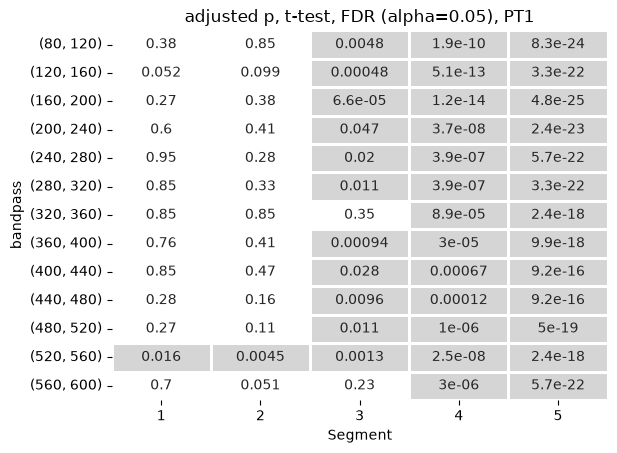

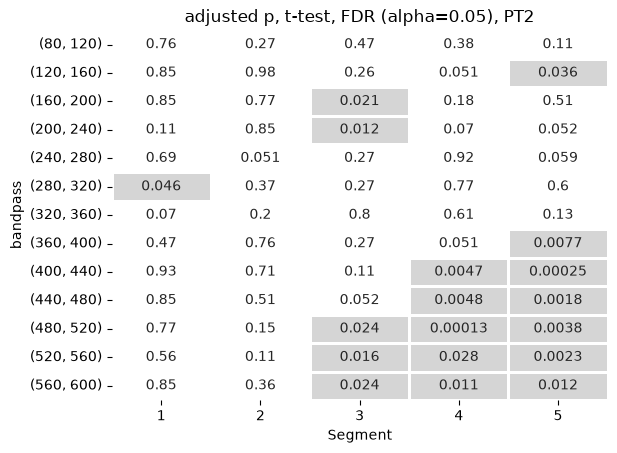

In [23]:
plot_ttest_results_pivot(pt='pt1', output_filename='aue_ttest_pt1.tiff', dpi=300)
plot_ttest_results_pivot(pt='pt2', output_filename='aue_ttest_pt2.tiff', dpi=300)

In [24]:
def df_table_fdr_significance(pt='pt1', output_csv=None):
    pt = pt

    df_ifsig = pivot_results(df_ttest_results, pt, 'reject')
    df_ifsig = df_ifsig.replace({True:'significant', False:'-'})
    #display(df_ifsig)
    if output_csv!=None:
        os.makedirs('csv', exist_ok=True)
        df_ifsig.to_csv(os.path.join('csv', output_csv), encoding='utf-8')
    return df_ifsig

In [25]:
df_ifsig_pt1 = df_table_fdr_significance(pt='pt1', output_csv='fdr_significance_pt1.csv')
df_ifsig_pt2 = df_table_fdr_significance(pt='pt2', output_csv='fdr_significance_pt2.csv')

In [26]:
def aue_to_df_csv(pt='pt1', hyp_type='evolving', output_csv=None, output_html=None):

    df_mean_std = df_ttest_results[df_ttest_results['pt']==pt].copy()
    df_mean_std['area under envelope'] = df_mean_std.apply(lambda x: f"{x['mean_'+hyp_type]:.3f}\u00B1{x['std_'+hyp_type]:.3f}", axis=1)
    df_mean_std = df_mean_std[['bp', 'segment', 'area under envelope']]
    df_mean_std = pd.pivot(df_mean_std, index='bp', columns='segment')
    df_mean_std = df_mean_std.sort_values('bp', key = lambda s: s.map(list_bp.index))

    if output_csv!=None:
        os.makedirs('csv', exist_ok=True)
        df_mean_std.to_csv(os.path.join('csv', output_csv), encoding='utf-8')
    return df_mean_std

In [27]:
df_mean_std_pt1_evolving = aue_to_df_csv(pt='pt1', hyp_type='evolving', output_csv='aue_pt1_evolving.csv')
df_mean_std_pt1_aborted = aue_to_df_csv(pt='pt1', hyp_type='aborted', output_csv='aue_pt1_aborted.csv')

df_mean_std_pt2_evolving = aue_to_df_csv(pt='pt2', hyp_type='evolving', output_csv='aue_pt2_evolving.csv')
df_mean_std_pt2_aborted = aue_to_df_csv(pt='pt2', hyp_type='aborted', output_csv='aue_pt2_aborted.csv')

In [28]:
display(df_mean_std_pt2_aborted)

area under envelope                                         \
segment               segment1     segment2     segment3     segment4   
bp                                                                      
(80, 120)          1.087±0.240  0.911±0.203  0.998±0.209  1.061±0.287   
(120, 160)         0.730±0.122  0.677±0.121  0.669±0.067  0.630±0.073   
(160, 200)         0.664±0.190  0.720±0.217  0.635±0.136  0.635±0.108   
(200, 240)         0.511±0.110  0.464±0.116  0.458±0.076  0.439±0.088   
(240, 280)         0.378±0.051  0.316±0.064  0.356±0.068  0.424±0.164   
(280, 320)         0.417±0.060  0.397±0.066  0.397±0.063  0.422±0.089   
(320, 360)         0.354±0.047  0.382±0.103  0.373±0.071  0.380±0.074   
(360, 400)         0.285±0.077  0.290±0.064  0.316±0.041  0.264±0.056   
(400, 440)         0.240±0.056  0.244±0.060  0.263±0.058  0.246±0.074   
(440, 480)         0.187±0.046  0.203±0.052  0.224±0.049  0.205±0.052   
(480, 520)         0.146±0.037  0.138±0.049  0.163±0.025  0.157±0.031   
(520, 560)         0.113±0.023  0.097±0.016  0.108±0.016  0.124±0.027   
(560, 600)         0.090±0.014  0.087±0.015  0.091±0.010  0.091±0.013   

                         
segment        segment5  
bp                       
(80, 120)   0.971±0.227  
(120, 160)  0.630±0.087  
(160, 200)  0.609±0.118  
(200, 240)  0.410±0.097  
(240, 280)  0.380±0.091  
(280, 320)  0.419±0.111  
(320, 360)  0.319±0.133  
(360, 400)  0.253±0.072  
(400, 440)  0.216±0.051  
(440, 480)  0.185±0.075  
(480, 520)  0.119±0.028  
(520, 560)  0.099±0.018  
(560, 600)  0.090±0.018

In [29]:
def plot_area_3d(pt='pt1', output_filename=None, dpi=300):

    pt = pt

    ifsig = pivot_results(df_ttest_results, pt, 'reject')
    num_lines = 13
    #colors = cm.cividis(np.linspace(0, 1, num_lines))
    cmap = plt.get_cmap('tab10')

    fig = plt.figure(figsize=(12, 12))
    ax = fig.add_subplot(111, projection='3d')

    for ind, bp in enumerate(list_bp):
        z_data_evolving = df_HYP[(df_HYP['pt']==pt)&(df_HYP['bp']==bp)&(df_HYP['type']=='evolving')]
        z_data_evolving = z_data_evolving[['segment'+str(n) for n in range(1, 6)]].to_numpy().mean(axis=0)
        z_data_evolving = np.log10(z_data_evolving)

        z_data_aborted = df_HYP[(df_HYP['pt']==pt)&(df_HYP['bp']==bp)&(df_HYP['type']=='aborted')]
        z_data_aborted = z_data_aborted[['segment'+str(n) for n in range(1, 6)]].to_numpy().mean(axis=0)
        z_data_aborted = np.log10(z_data_aborted)
        x_data = np.arange(1, 6)
        y_data = np.ones(5)*(12-ind)

        ax.plot(x_data, y_data, z_data_evolving, color=cmap(ind%10), linestyle='-', lw=2, marker='.', markersize=10)
        ax.plot(x_data, y_data, z_data_aborted, color=cmap(ind%10), linestyle='--', lw=1.5, marker='.', markersize=10)

        for n_seg in range(1, 6):
            if ifsig.loc[bp, 'segment'+str(n_seg)].item()==True:
                ax.plot([n_seg, n_seg], [12-ind, 12-ind], [z_data_evolving[n_seg-1], z_data_aborted[n_seg-1]], color=cmap(ind%10), linestyle=':', alpha=0.8, lw=3)

    ax.xaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.yaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.zaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))

    ax.zaxis.set_rotate_label(False)

    ax.set_xlabel('Segment', labelpad=4, fontsize=13)
    ax.set_ylabel('frequency band', labelpad=15, fontsize=13)
    ax.set_zlabel('Area (\u03bcV.s, log scale)', labelpad=8, fontsize=13, rotation=93)
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_yticks([n for n in range(0, 13)])
    ax.set_yticklabels([list_bp[-1], '', '', '', '', list_bp[7], '', '', '', '', list_bp[2], '', list_bp[0]])
    z_ticks_labels = [0.4, 0.6, 0.8, 1.0]
    z_ticks_values = list(np.log(z_ticks_labels))
    ax.set_zticks(z_ticks_values)
    ax.set_zticklabels(z_ticks_labels)

    ax.set_box_aspect((1, 1.5, 1.5))

    # set legend
    legend_elements = []
    legend_elements.append(Line2D([0], [0], color='none', label='bandpass'))
    for ind, bp in enumerate(list_bp):
        legend_elements.append(Line2D([0], [0], color=cmap(ind%10), label=bp, lw=2))

    legend_elements.append(Line2D([0], [0], color='none', label='type'))
    for ls, label in zip(['-', '--'], ['evolving', 'aborted']):
        legend_elements.append(Line2D([0], [0], color='black', linestyle=ls, label=label, lw=2))
    legend_elements.append(Line2D([0], [0], color='none', label='difference'))
    legend_elements.append(Line2D([0], [0], color='black', alpha=0.8, linestyle=':', label='significant'))

    fig.legend(handles=legend_elements, bbox_to_anchor=(.9, .85), fontsize=13)

    ax.xaxis._axinfo["grid"].update({'linewidth': 0.3, 'color': 'lightgray'})
    ax.yaxis._axinfo["grid"].update({'linewidth': 0.3, 'color': 'lightgray'})
    ax.zaxis._axinfo["grid"].update({'linewidth': 0.3, 'color': 'lightgray'})

    # Optimize the viewpoint (Height, Rotation)
    ax.view_init(elev=30, azim=-135)

    if output_filename!=None:
        os.makedirs('figures', exist_ok=True)
        fig.savefig(os.path.join('figures', output_filename), dpi=dpi, facecolor='white')


    plt.show()



In [30]:
def plot_area_3d_fill(pt='pt1', output_filename=None, dpi=300):

    pt = pt

    ifsig = pivot_results(df_ttest_results, pt, 'reject')
    #num_lines = 13
    #colors = cm.cividis(np.linspace(0, 1, num_lines))
    cmap = plt.get_cmap('tab10')

    fig = plt.figure(figsize=(12, 9))
    ax = fig.add_subplot(111, projection='3d')

    ax.set_title('The area under envelop vs segment: '+pt.upper(), fontsize=18)


    for ind, bp in enumerate(list_bp):

        label_bp = bp.replace('(', '').replace(')', '').split(', ')
        label_bp = label_bp[0]+'-'+label_bp[1]+' Hz'
        z_data_evolving = df_HYP[(df_HYP['pt']==pt)&(df_HYP['bp']==bp)&(df_HYP['type']=='evolving')]
        z_data_evolving = z_data_evolving[['segment'+str(n) for n in range(1, 6)]].to_numpy().mean(axis=0)
        z_data_evolving = np.log10(z_data_evolving)

        z_data_aborted = df_HYP[(df_HYP['pt']==pt)&(df_HYP['bp']==bp)&(df_HYP['type']=='aborted')]
        z_data_aborted = z_data_aborted[['segment'+str(n) for n in range(1, 6)]].to_numpy().mean(axis=0)
        z_data_aborted = np.log10(z_data_aborted)
        x_data = np.arange(1, 6)
        y_data = np.ones(5)*(12-ind)

        ifsig_bp = ifsig.loc[bp].to_numpy()

        ax.plot(x_data, y_data, z_data_evolving, color=cmap(ind%10), linestyle='-', lw=2, marker=None)
        ax.plot(x_data, y_data, z_data_aborted, color=cmap(ind%10), linestyle='--', lw=1.5, marker=None)

        ax.scatter(x_data[ifsig_bp], y_data[ifsig_bp], z_data_evolving[ifsig_bp], \
                   s=35, edgecolors=cmap(ind%10), color='w', marker='o', linewidth=1, alpha=1.0)
        ax.scatter(x_data[ifsig_bp], y_data[ifsig_bp], z_data_aborted[ifsig_bp], \
                   s=35, edgecolors=cmap(ind%10), color='w', marker='o', linewidth=1, alpha=1.0)
        ax.scatter(x_data[~ifsig_bp], y_data[~ifsig_bp], z_data_evolving[~ifsig_bp], \
                   s=15, color=cmap(ind%10), marker='o', alpha=1.0)
        ax.scatter(x_data[~ifsig_bp], y_data[~ifsig_bp], z_data_aborted[~ifsig_bp], \
                   s=15, color=cmap(ind%10), marker='o', alpha=1.0)
        
        #ax.plot(x_data, y_data, np.full(5, np.log10(min_aue).item()), color='k')
        ax.text(x_data[-1]+.2, y_data[-1], z_data_evolving[-1], label_bp, 'x', fontsize=12)
        
        #ax.fill_between(x_data, y_data, z_data_aborted, x_data, y_data, np.full(5, np.log10(min_aue).item()), facecolors=cmap(ind%10), alpha=0.1)
        ax.fill_between(x_data, y_data, z_data_aborted, x_data, y_data, z_data_evolving, facecolors=cmap(ind%10), alpha=0.1)

        for n_seg in range(1, 6):
            if ifsig_bp[n_seg-1]==True:
                ax.plot([n_seg, n_seg], [12-ind, 12-ind], [z_data_evolving[n_seg-1], z_data_aborted[n_seg-1]], color=cmap(ind%10), linestyle=':', alpha=0.8, lw=2)

    ax.xaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.yaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.zaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))

    ax.zaxis.set_rotate_label(False)

    ax.set_xlabel('Segment', labelpad=2, fontsize=13)
    ax.set_ylabel('frequency band', labelpad=0, fontsize=13)
    ax.set_zlabel('Area (\u03bcV.s, log scale)', labelpad=8, fontsize=13, rotation=93)
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_xticklabels([1, 2, 3, 4, 5], fontsize=12)
    ax.set_yticks([n for n in range(0, 13)])
    ax.set_yticklabels([])
    #ax.set_yticklabels([list_bp[-1], '', '', '', '', list_bp[7], '', '', '', '', list_bp[2], '', list_bp[0]])
    z_ticks_labels = [0.4, 0.6, 0.8, 1.0]
    z_ticks_values = list(np.log(z_ticks_labels))
    ax.set_zticks(z_ticks_values)
    ax.set_zticklabels(z_ticks_labels, fontsize=12)

    ax.set_box_aspect((1, 1.5, 1.5))

    # set legend
    legend_elements = []
    #legend_elements.append(Line2D([0], [0], color='none', label='bandpass'))
    #for ind, bp in enumerate(list_bp):
    #    legend_elements.append(Line2D([0], [0], color=cmap(ind%10), label=bp, lw=2))

    legend_elements.append(Line2D([0], [0], color='none', label='type'))
    for ls, label, lw in zip(['-', '--'], ['evolving', 'aborted'], [2, 1.5]):
        legend_elements.append(Line2D([0], [0], color='black', linestyle=ls, label=label, lw=lw))
    legend_elements.append(Line2D([0], [0], color='none', label='\nsignificance'))
    legend_elements.append(Line2D([0], [0], linestyle=None, label='significant', \
                                  color='white', marker='o', markerfacecolor='white', markeredgecolor='black', markersize=7))
    legend_elements.append(Line2D([0], [0], linestyle=None, label='non-significant', \
                                  color='white', marker='o', markerfacecolor='black', markeredgecolor='black', markersize=7))

    fig.legend(handles=legend_elements, bbox_to_anchor=(.85, .85), fontsize=12)

    ax.xaxis._axinfo["grid"].update({'linewidth': 0.3, 'color': 'lightgray'})
    ax.yaxis._axinfo["grid"].update({'linewidth': 0.3, 'color': 'lightgray'})
    ax.zaxis._axinfo["grid"].update({'linewidth': 0.3, 'color': 'lightgray'})

    # Optimize the viewpoint (Height, Rotation)
    ax.view_init(elev=30, azim=-135)

    #ax.computed_zorder = False

    if output_filename!=None:
        os.makedirs('figures', exist_ok=True)
        fig.savefig(os.path.join('figures', output_filename), dpi=dpi)


    plt.show()



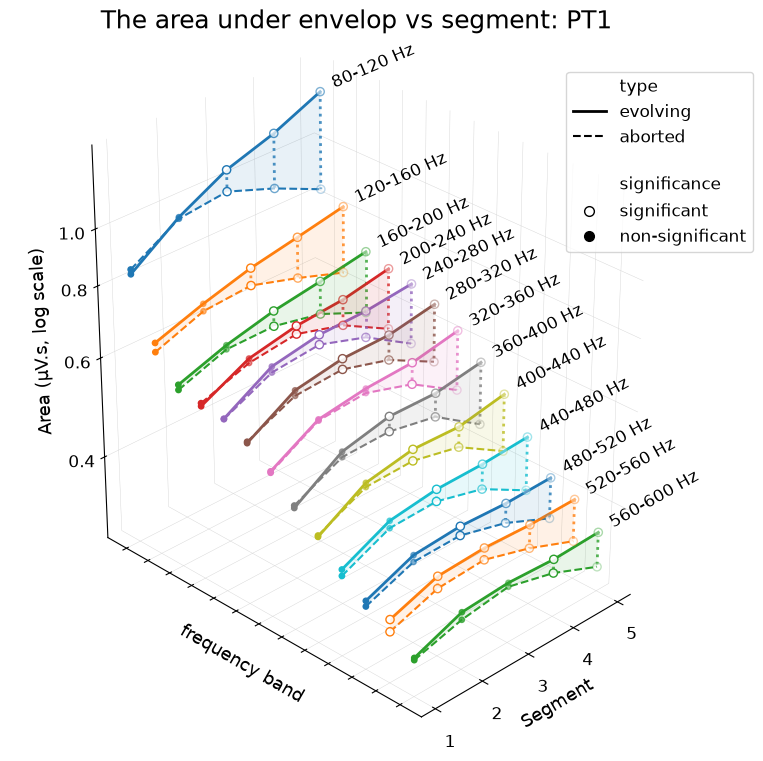

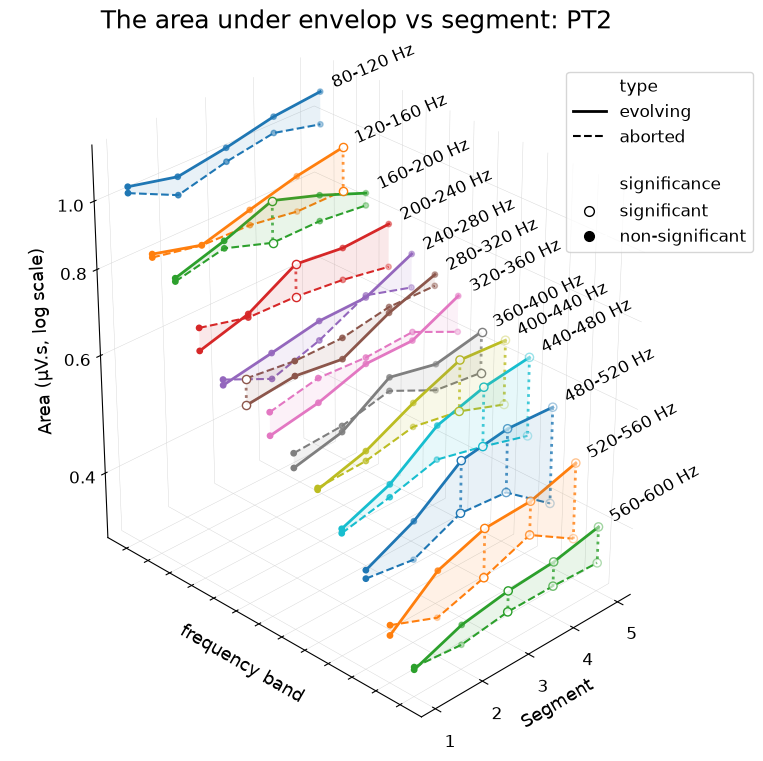

In [31]:
plot_area_3d_fill(pt='pt1', output_filename='area_under_envelope_3d_plot_pt1.svg')
plot_area_3d_fill(pt='pt2', output_filename='area_under_envelope_3d_plot_pt2.svg')

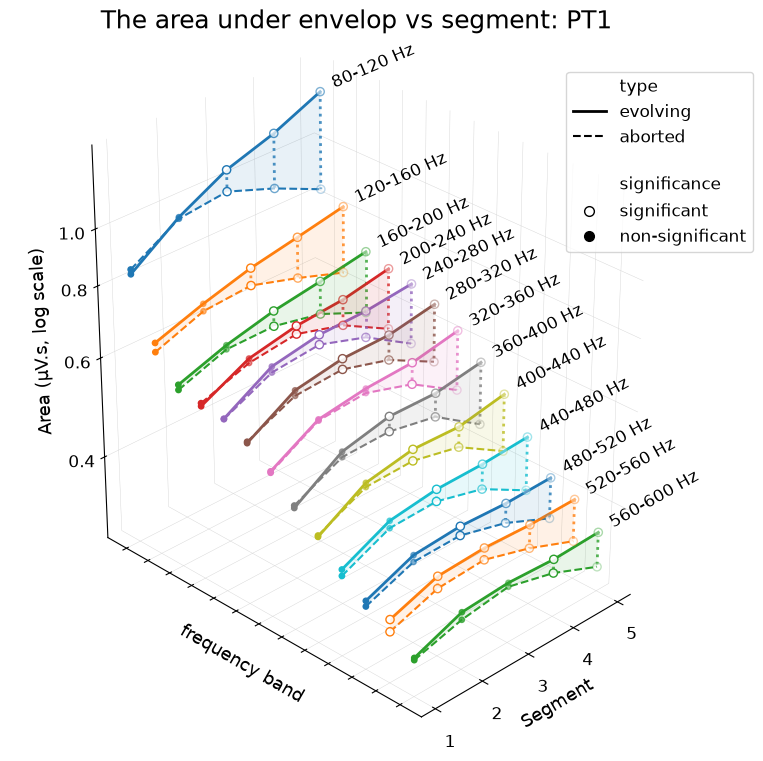

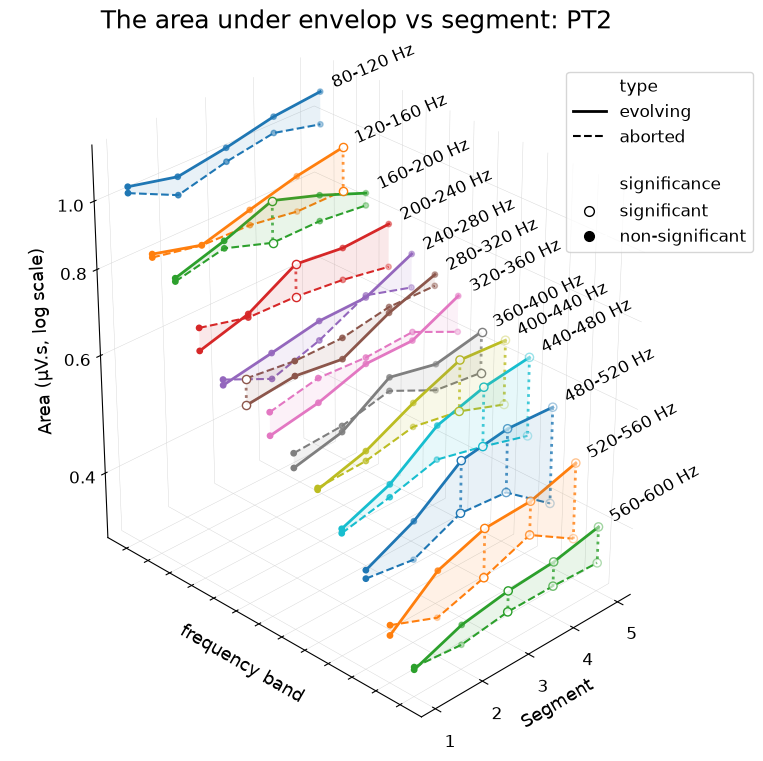

In [32]:
plot_area_3d_fill(pt='pt1', output_filename='area_under_envelope_3d_plot_pt1.tiff', dpi=300)
plot_area_3d_fill(pt='pt2', output_filename='area_under_envelope_3d_plot_pt2.tiff', dpi=300)

## Spectrogram Analysis

In [33]:
## baseline
baseline = {}

for pt in ['pt1', 'pt2']:
    with open(f'data/baseline_data_{pt}.pickle', 'rb') as f:
        baseline_data = pickle.load(f)

    f_list, t_list, sxx = signal.spectrogram(baseline_data, 2000, nperseg=200, noverlap=175, window='han')
    baseline[pt] = 20*np.log10(np.abs(sxx))
    baseline[pt] = np.median(baseline[pt], axis=1)
del f_list, t_list, sxx, baseline_data

In [34]:
def averaged_spectrogram_analysis(list_hyp):

    backstep=1000
    forwardstep=1000
    step = np.arange(-backstep, forwardstep+1)
    t_step = step*0.0005
    N=5 # number of segments
    nperseg = 200
    noverlap = 175
    fs = 2000

    #to store averaged spectrogram in each segment and in each HYP, list_list_spectro_evolving[n_HYP][segment]
    list_list_spectro = []

    for ind_l, l in enumerate(list_hyp):
        t_peaks = l.np_data[:, 4]
        seg_t = np.floor((t_peaks-t_peaks.min())/(t_peaks.max()-t_peaks.min())*N).astype('int64')
        seg_t[seg_t==N]=N-1

        list_spectro = [] # to store averaged spectrograms in each segment

        for i in range(N):
            temp_list_spectro = [] # to store raw spectrograms in each segment
            for t in t_peaks[seg_t==i]:
                i_tpeak = int(np.where(l.time==t)[0].item())
                if i_tpeak>backstep:
                    temp_discharge = l.eeg[i_tpeak-backstep:i_tpeak+forwardstep+1]
                    f_list, t_list, sxx = signal.spectrogram(temp_discharge, fs, nperseg=nperseg, noverlap=noverlap, window='han')
                    temp_list_spectro.append(sxx)
                #print('sxx shape: {}, f_list: {}, t_list: {}'.format(sxx.shape, f_list.shape, t_list.shape))

            temp_ave_spectro= np.mean(np.array(temp_list_spectro), axis = 0)

            # change to dB
            temp_ave_spectro = 20*np.log10(np.abs(temp_ave_spectro))

            list_spectro.append(temp_ave_spectro)
            print('index of HYP={}, segment {}. n discharges={}'.format(ind_l, i+1, len(temp_list_spectro)))

        list_list_spectro.append(list_spectro)

        averaged_spectro_db = np.array(list_list_spectro).mean(axis=0)

    return averaged_spectro_db, np.array(list_list_spectro), t_list, f_list

In [35]:
averaged_spectrogram_seg = {}
averaged_spectrogram_all = {}

for k, v in dict_list_hyp.items():
    averaged_spectrogram_seg[k], averaged_spectrogram_all[k], t_list, f_list = averaged_spectrogram_analysis(v)

index of HYP=0, segment 1. n discharges=2
index of HYP=0, segment 2. n discharges=3
index of HYP=0, segment 3. n discharges=5
index of HYP=0, segment 4. n discharges=5
index of HYP=0, segment 5. n discharges=3
index of HYP=1, segment 1. n discharges=2
index of HYP=1, segment 2. n discharges=2
index of HYP=1, segment 3. n discharges=3
index of HYP=1, segment 4. n discharges=4
index of HYP=1, segment 5. n discharges=2
index of HYP=2, segment 1. n discharges=2
index of HYP=2, segment 2. n discharges=2
index of HYP=2, segment 3. n discharges=3
index of HYP=2, segment 4. n discharges=3
index of HYP=2, segment 5. n discharges=3
index of HYP=3, segment 1. n discharges=4
index of HYP=3, segment 2. n discharges=4
index of HYP=3, segment 3. n discharges=4
index of HYP=3, segment 4. n discharges=5
index of HYP=3, segment 5. n discharges=6
index of HYP=4, segment 1. n discharges=2
index of HYP=4, segment 2. n discharges=2
index of HYP=4, segment 3. n discharges=3
index of HYP=4, segment 4. n disch

In [36]:
def plot_averaged_spectrograms(key, N=5, t_list=t_list, f_list=f_list, output_filename=None, dpi=300):

    hyp_type, pt = key.split('_')
    spectrograms = averaged_spectrogram_seg[key]

    fs_legend = 7
    fs_xylabel = 9
    l_width = 2
    fs_title = 10

    fig, ax = plt.subplots(1, 6, figsize=(16, 3), gridspec_kw={'width_ratios': [1, 1, 1, 1, 1, 0.05]})

    # baseline corrected
    fig.suptitle(f'Superimposed spectrogram of discharges: {pt.upper()}, HYP-{hyp_type}', fontsize=14, y=1.03)

    for i in range(0, N):
        mappable = ax[i].pcolormesh(t_list-0.5, f_list, spectrograms[i, :, :]-baseline[pt].reshape(-1, 1), shading='auto', cmap='jet', vmin=-60, vmax=60)
        ax[i].set_ylim(0, 600)
        ax[i].set_title('Segment {}'.format(i+1), fontsize=fs_title)
        if i==0:
            ax[i].set_ylabel('Freq. (Hz)', fontsize=fs_xylabel)
        else:
            ax[i].tick_params(labelleft=False)
        ax[i].set_xlabel('Time (s): t=0 at discharge peak', fontsize=fs_xylabel)
        ax[i].set_xlim(-0.3, 0.3)
    clb = plt.colorbar(mappable=mappable, cax=ax[5])
    clb.ax.set_title('(dB)')
    #plt.tight_layout()

    if output_filename!=None:
        os.makedirs('figures', exist_ok=True)
        fig.savefig(os.path.join('figures', output_filename), facecolor='white', bbox_inches='tight', dpi=dpi)
    plt.show()

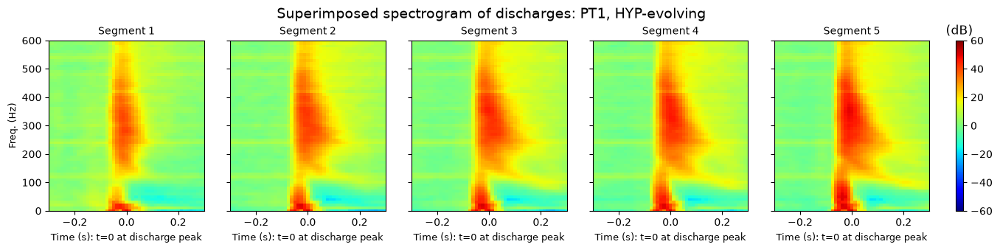

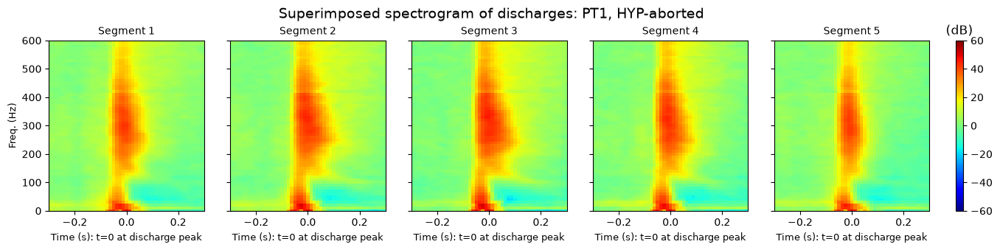

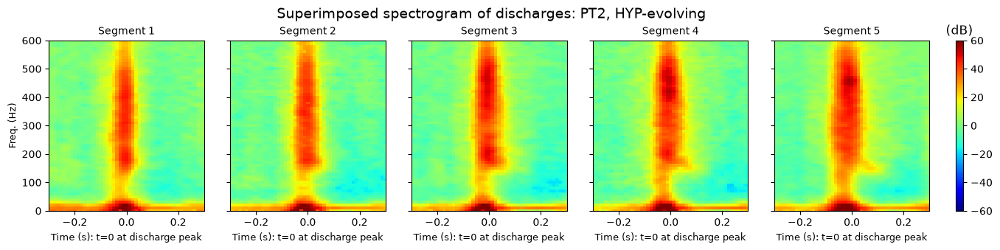

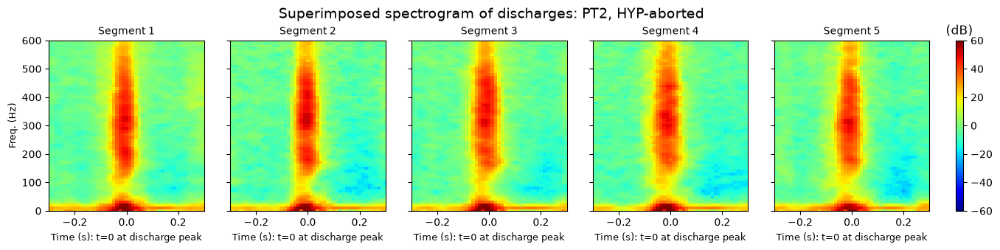

In [37]:
for key in averaged_spectrogram_seg.keys():
    plot_averaged_spectrograms(key, output_filename="superimposed_spec_"+key+'.tiff', dpi=300)

## t-test for spectrograms

In [38]:
lim_f = f_list<=600
lim_t = (0.2<=t_list)&(t_list<=0.8)

f_list_limited = f_list[lim_f]
t_list_limited = t_list[lim_t]-0.5

In [39]:
def ttest_spectrogram_evolving_vs_aborted(pt='pt1'):
    pt = pt

    spectro_evolving = averaged_spectrogram_all['evolving_'+pt][:, :, lim_f, :][:, :, :, lim_t]
    spectro_aborted = averaged_spectrogram_all['aborted_'+pt][:, :, lim_f, :][:, :, :, lim_t]

    len_i0, len_i1, len_i2, len_i3 = spectro_evolving.shape

    pval_t_unadj = np.zeros((len_i1, len_i2, len_i3))

    for i1, i2, i3 in np.ndindex(len_i1, len_i2, len_i3):
        tval, pval_t_unadj[i1, i2, i3], df = ttest_ind(spectro_evolving[:, i1, i2, i3], spectro_aborted[:, i1, i2, i3])

    return pval_t_unadj

In [40]:
pval_t_unadj = {}

for pt in ['pt1', 'pt2']:
    pval_t_unadj[pt] = ttest_spectrogram_evolving_vs_aborted(pt)

concat_pval_t_unadj = np.array(list(pval_t_unadj.values()))

spec_fdr_results = multi.multipletests(concat_pval_t_unadj.flatten(), alpha=0.05, method='fdr_bh')[1].reshape(concat_pval_t_unadj.shape)

In [41]:
pval_t_adj = {}

for i, pt in zip(range(spec_fdr_results.shape[0]), ['pt1', 'pt2']):
    pval_t_adj[pt] = spec_fdr_results[i, :, :, :]

In [42]:
def plot_pval(pt, N=5, t_list=t_list, f_list=f_list, output_filename=None, dpi=300):

    pt = pt
    spectrograms = pval_t_adj[pt]

    fs_legend = 7
    fs_xylabel = 9
    l_width = 2
    fs_title = 10

    fig, ax = plt.subplots(1, 6, figsize=(16, 3), gridspec_kw={'width_ratios': [1, 1, 1, 1, 1, 0.05]})

    # baseline corrected
    fig.suptitle(f'p-values, t-test of spectrograms, HYP-evolving vs -aborted: {pt.upper()}', fontsize=14, y=1.03)

    for i in range(0, N):
        mappable = ax[i].pcolormesh(t_list_limited, f_list_limited, spectrograms[i, :, :], shading='auto', cmap='viridis', vmin=0., vmax=.1)
        ax[i].set_ylim(0, 600)
        ax[i].set_title('Segment {}'.format(i+1), fontsize=fs_title)
        if i==0:
            ax[i].set_ylabel('Freq. (Hz)', fontsize=fs_xylabel)
        else:
            ax[i].tick_params(labelleft=False)
        ax[i].set_xlabel('Time (s): t=0 at discharge peak', fontsize=fs_xylabel)
        ax[i].set_xlim(-0.3, 0.3)
    clb = plt.colorbar(mappable=mappable, cax=ax[5])
    clb.ax.set_title('p')
    #plt.tight_layout()
    if output_filename!=None:
        os.makedirs('figures', exist_ok=True)
        fig.savefig(os.path.join('figures', output_filename), dpi=dpi, bbox_inches='tight', facecolor='white')
    plt.show()

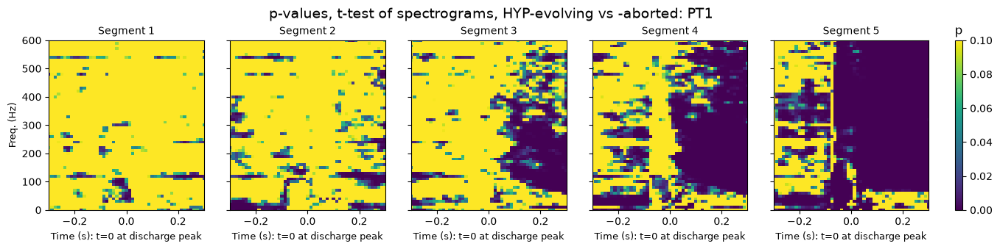

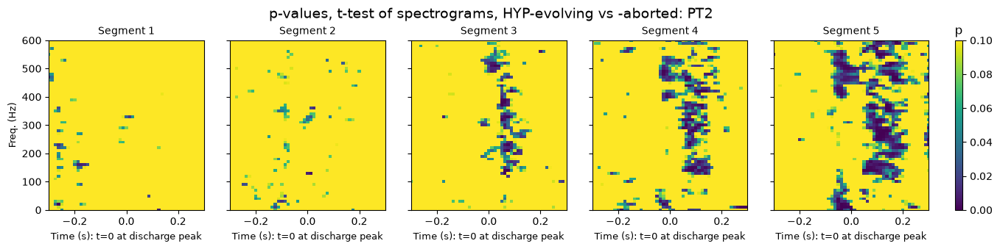

In [43]:
plot_pval('pt1', output_filename='pval_ttest_spectrogram_pt1.tiff', dpi=300)
plot_pval('pt2', output_filename='pval_ttest_spectrogram_pt2.tiff', dpi=300)

## difference of spectrogram

In [44]:
def plot_spectrogram_difference(pt='pt1', vmin=-30, vmax=40, output_filename=None, dpi=300):

    fig, ax = plt.subplots(3, 6, figsize=(17.5/2.54, 11/2.54),
                        gridspec_kw={'width_ratios': [1, 1, 1, 1, 1, 0.07]})

    fs_legend = 7
    fs_xylabel = 9
    fs_clbticks = 9
    l_width = 2
    fs_title = 10

    n_evolving = averaged_spectrogram_all['evolving_'+pt].shape[0]
    n_aborted = averaged_spectrogram_all['aborted_'+pt].shape[0]

    fig.suptitle(f'Averaged spectrogram, {pt.upper()}', fontsize=12, y=.95)

    spectro_evolving = averaged_spectrogram_seg['evolving_'+pt][:, lim_f, :][:, :, lim_t]
    spectro_aborted = averaged_spectrogram_seg['aborted_'+pt][:, lim_f, :][:, :, lim_t]
    baseline_lim = baseline[pt][lim_f].reshape(-1, 1)
    pval = pval_t_adj[pt]
    alpha = 0.05

    # plot ave spectro of HYP-evolving
    for i in range(5):
        mappable = ax[0][i].pcolormesh(t_list_limited,f_list_limited, spectro_evolving[i, :, :]-baseline_lim, shading='auto', cmap='jet', vmin=vmin, vmax=vmax)
        #fig.colorbar()
        ax[0][i].set_ylim(0, 600)
        #ax[0][i].set_title('Segment {}'.format(i+1), fontsize=fs_title)
        if i==0:
            ax[0][i].set_ylabel('Freq. (Hz)', fontsize=fs_xylabel)
        else:
            ax[0][i].tick_params(labelleft=False)
        #ax[0][i].set_xlabel('Time (s): t=0 at discharge peak', fontsize=fs_xylabel)
        ax[0][i].set_xticks(np.arange(-0.2, 0.21, 0.1))
        ax[0][i].tick_params(labelbottom=False)
        ax[0][i].set_xlim(-0.3, 0.3)
    clb = plt.colorbar(mappable=mappable, cax=ax[0][5])
    clb.ax.set_title('(dB)', fontsize=9)
    clb.ax.tick_params(labelsize=fs_clbticks)
    #fig.tight_layout()

    # plot ave spectro HYP-aborted
    for i in range(5):
        mappable = ax[1][i].pcolormesh(t_list_limited, f_list_limited, spectro_aborted[i, : :]-baseline_lim, shading='auto', cmap='jet', vmin=vmin, vmax=vmax)
        ax[1][i].set_ylim(0, 600)
        if i==0:
            ax[1][i].set_ylabel('Freq. (Hz)', fontsize=fs_xylabel)
        else:
            ax[1][i].tick_params(labelleft=False)
        ax[1][i].set_xticks(np.arange(-0.2, 0.21, 0.1))
        ax[1][i].tick_params(labelbottom=False)
        ax[1][i].set_xlim(-0.3, 0.3)
    clb = plt.colorbar(mappable=mappable, cax=ax[1][5])
    clb.ax.tick_params(labelsize=fs_clbticks)

    diff_spectro = spectro_evolving[i, :, :]-spectro_aborted[i, :, :]
    diff_spectro_masked = np.where(pval<alpha, diff_spectro, np.nan)

    for i in range(0, 5):
        mappable = ax[2][i].pcolormesh(t_list_limited, f_list_limited, diff_spectro_masked[i, :, :], shading='auto', cmap='jet', vmin=-35, vmax=35)
        ax[2][i].set_ylim(0, 600)
        if i==0:
            ax[2][i].set_ylabel('Freq. (Hz)', fontsize=fs_xylabel)
        else:
            ax[2][i].tick_params(labelleft=False)
        ax[2][i].set_xticks(np.arange(-0.2, 0.21, 0.2))
        ax[2][i].set_xlabel('Time (s)')
        ax[2][i].tick_params(axis='x', labelsize=fs_xylabel-1)
        ax[2][i].set_xlim(-0.3, 0.3)
    clb = plt.colorbar(mappable=mappable, cax=ax[2][5])
    clb.ax.tick_params(labelsize=fs_clbticks)
    #clb.ax.set_title('(dB)')

    col_headers=['col {}'.format(n) for n in list(range(5))]
    row_headers=['row {}'.format(n) for n in list(range(3))]

    for i, l in enumerate([f'HYP-evolving\n(n={n_evolving})', f'HYP-aborted\n(n={n_aborted})', 'difference\n(evolving-aborted)']):
        ax[i][0].annotate(l, xy=(0, .5), xytext=(-ax[i][0].yaxis.labelpad-15, 0),
                        xycoords=ax[i][0].yaxis.label, textcoords='offset points',
                        ha='center', va='center', rotation=90, weight='bold', fontsize=8)

    for i, l in enumerate(['Segment {}'.format(k) for k in list(range(1, 6))]):
        ax[0][i].annotate(l, xy=(0.5, 1), xytext=(0, 8),
                        xycoords='axes fraction', textcoords='offset points',
                        ha='center', va='baseline', weight='bold', fontsize=10)


    plt.tight_layout()
    fig.subplots_adjust(hspace=0.12, wspace=.07)

    if output_filename!=None:
        os.makedirs('figures', exist_ok=True)
        fig.savefig(os.path.join('figures', output_filename), dpi=dpi, bbox_inches='tight', facecolor='white')
    plt.show()

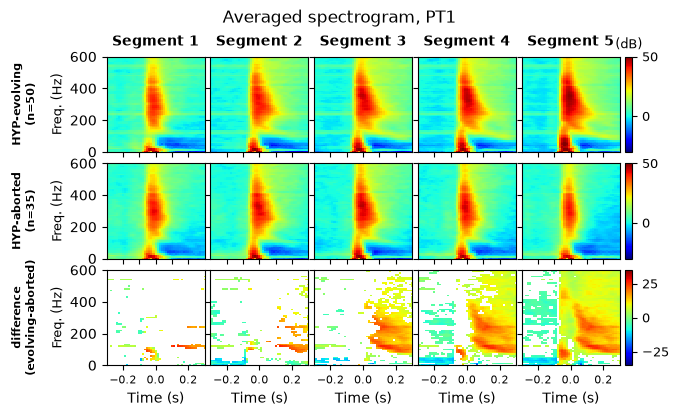

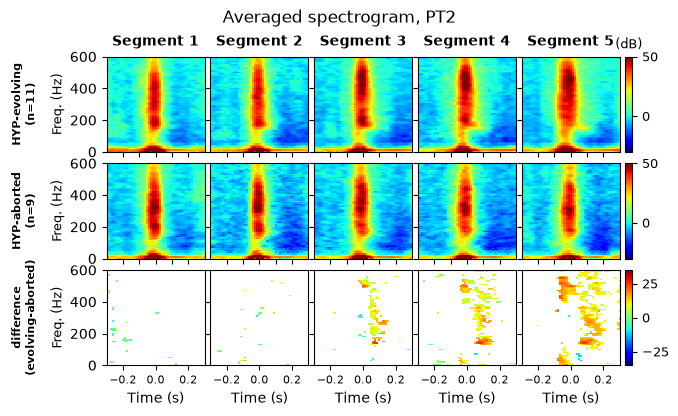

In [45]:
plot_spectrogram_difference(pt='pt1', output_filename='spectrogram_diff_pt1.tiff', vmin=-30, vmax=50, dpi=300)
plot_spectrogram_difference(pt='pt2', output_filename='spectrogram_diff_pt2.tiff', vmin=-30, vmax=50, dpi=300)